# ch04_1. Fashion-MNIST CNN 학습과 평가

## 개요

- CNN 구조를 Fashion-MNIST에 적용합니다.
- `nn.Sequential`로 간단한 CNN을 구성합니다.

## 공통 설정

데이터·모델·이미지 폴더 위치를 지정합니다.

In [2]:
from pathlib import Path

DATA_DIR = Path("data")
MODEL_DIR = Path("models")
PNG_DIR = Path("png")

DATA_DIR.mkdir(exist_ok=True)

MODEL_DIR.mkdir(exist_ok=True)
PNG_DIR.mkdir(exist_ok=True)

print("데이터 폴더:", DATA_DIR)
print("모델 폴더  :", MODEL_DIR)
print("이미지 폴더:", PNG_DIR)


데이터 폴더: data
모델 폴더  : models
이미지 폴더: png


## 공통 import

In [3]:
import copy
from pathlib import Path
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from torchvision.utils import make_grid
import matplotlib.pyplot as plt

### 1) 실행 장치 확인

```text
Conv2d·ReLU·MaxPool2d의 역할
→ 필터와 특징맵
→ 계층별 Shape 변화
```

```text
Fashion-MNIST 준비
→ CNN 학습
→ 검증 최고 모델 선택
→ 테스트 평가
→ MLP와 비교할 기준 결과 확보
→ Checkpoint 저장
```

```text
Fashion-MNIST 다운로드
→ 훈련·검증·테스트 구성
→ 기본 CNN 생성
→ Shape와 파라미터 확인
→ 10 Epoch 학습
→ 최고 검증 가중치 복원
→ 테스트 최종 평가
→ 혼동행렬·클래스별 정확도
→ 대표 오답
→ 2픽셀 이동 민감도
→ Checkpoint 저장
```

GPU를 사용할 수 있으면 CUDA(쿠다, 엔비디아 GPU 연산 환경)를 사용하고, 그렇지 않으면 CPU를 사용합니다.

In [4]:
RANDOM_SEED = 42

torch.manual_seed(RANDOM_SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("사용 장치:", device)

사용 장치: cuda


### 2) 학습 설정과 의류 클래스

Fashion-MNIST는 28×28 흑백 의류 이미지 10종으로 구성됩니다.

| 번호 | 클래스 |
|---:|---|
| 0 | 티셔츠 |
| 1 | 바지 |
| 2 | 풀오버 |
| 3 | 원피스 |
| 4 | 코트 |
| 5 | 샌들 |
| 6 | 셔츠 |
| 7 | 운동화 |
| 8 | 가방 |
| 9 | 앵클부츠 |

In [5]:
BATCH_SIZE = 128

NUMBER_OF_EPOCHS = 10

LEARNING_RATE = 0.001

VALIDATION_SIZE = 5_000

class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

class_names_ko = [
    "티셔츠",
    "바지",
    "풀오버",
    "원피스",
    "코트",
    "샌들",
    "셔츠",
    "운동화",
    "가방",
    "앵클부츠"
]

print("Batch Size:", BATCH_SIZE)

print("Epoch:", NUMBER_OF_EPOCHS)

print("Learning Rate:", LEARNING_RATE)

Batch Size: 128
Epoch: 10
Learning Rate: 0.001


### 3) DataLoader 준비

훈련 데이터 60,000개를 다음과 같이 나눕니다.

```text
학습 데이터 55,000개
→ 필터와 가중치 학습

검증 데이터 5,000개
→ 가장 좋은 Epoch 선택

테스트 데이터 10,000개
→ 최종 성능 평가
```

`ToTensor()`는 이미지를 Tensor로 바꾸고 픽셀값을 0과 1 사이로 변환합니다.

In [6]:
transform = transforms.ToTensor()

full_train_dataset = datasets.FashionMNIST(
    root=str(DATA_DIR / "torchvision"),
    train=True,
    transform=transform,
    download=True
)

test_dataset = datasets.FashionMNIST(
    root=str(DATA_DIR / "torchvision"),
    train=False,
    transform=transform,
    download=True
)

train_size = (
    len(full_train_dataset)
    - VALIDATION_SIZE
)

split_generator = torch.Generator().manual_seed(
    RANDOM_SEED
)

train_dataset, validation_dataset = random_split(
    full_train_dataset,
    [train_size, VALIDATION_SIZE],
    generator=split_generator
)

loader_generator = torch.Generator().manual_seed(
    RANDOM_SEED
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=loader_generator
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

### 4) DataLoader 준비

In [7]:
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("학습 데이터:", len(train_dataset))

print("검증 데이터:", len(validation_dataset))

print("테스트 데이터:", len(test_dataset))

학습 데이터: 55000
검증 데이터: 5000
테스트 데이터: 10000


### 5) 배치 데이터 확인

CNN 입력 순서는 `[N, C, H, W]`입니다.

```text
N: 이미지 수
C: 채널 수
H: 높이
W: 너비
```

Fashion-MNIST 한 Batch의 Shape:

```text
[128, 1, 28, 28]
```

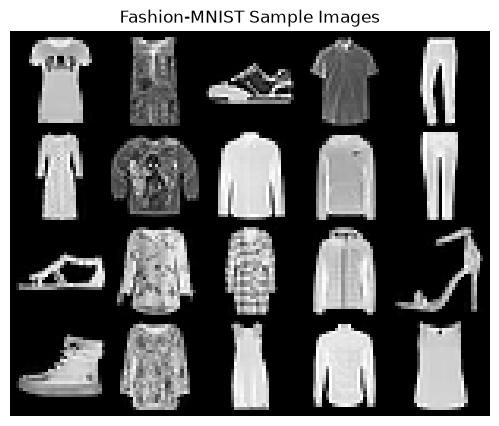

배치 이미지 Shape: torch.Size([128, 1, 28, 28])
배치 정답 Shape: torch.Size([128])

표시된 이미지의 실제 클래스
0: 티셔츠
1: 셔츠
2: 운동화
3: 셔츠
4: 바지
5: 원피스
6: 풀오버
7: 셔츠
8: 코트
9: 바지


In [8]:
sample_images, sample_labels = next(
    iter(train_loader)
)

sample_grid = make_grid(
    sample_images[:20],
    nrow=5,
    padding=2
)

plt.figure(figsize=(10, 5))

plt.imshow(
    sample_grid.permute(1, 2, 0)
)

plt.title("Fashion-MNIST Sample Images")

plt.axis("off")

plt.show()

print("배치 이미지 Shape:", sample_images.shape)

print("배치 정답 Shape:", sample_labels.shape)

print()

print("표시된 이미지의 실제 클래스")

for index in range(10):
    print(
        f"{index}: "
        f"{class_names_ko[sample_labels[index].item()]}"
    )

### 6) 모델 구성

아래 CNN 구조를 실제 데이터에 적용합니다.

```text
입력 [N, 1, 28, 28]

→ Conv2d(1, 8, 3, padding=1)
→ ReLU
→ MaxPool2d(2, 2)
→ [N, 8, 14, 14]

→ Conv2d(8, 16, 3, padding=1)
→ ReLU
→ MaxPool2d(2, 2)
→ [N, 16, 7, 7]

→ Flatten
→ [N, 784]

→ Linear(784, 10)
→ [N, 10]
```

별도의 사용자 정의 모델 클래스 없이 `nn.Sequential`을 사용합니다.

In [9]:
def make_cnn():
    return nn.Sequential(
        nn.Conv2d(
            1,
            8,
            kernel_size=3,
            padding=1
        ),
        nn.ReLU(),
        nn.MaxPool2d(
            kernel_size=2,
            stride=2
        ),

        nn.Conv2d(
            8,
            16,
            kernel_size=3,
            padding=1
        ),
        nn.ReLU(),
        nn.MaxPool2d(
            kernel_size=2,
            stride=2
        ),

        nn.Flatten(start_dim=1),
        nn.Linear(
            16 * 7 * 7,
            10
        )
    )

torch.manual_seed(RANDOM_SEED)

model = make_cnn().to(device)

print(model)

Sequential(
  (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=784, out_features=10, bias=True)
)


### 7) 계층별 Shape와 파라미터 확인

실제 Batch가 예상한 Shape로 통과하는지만 확인합니다.

In [10]:
layer_names = [
    "Conv1",
    "ReLU1",
    "Pool1",
    "Conv2",
    "ReLU2",
    "Pool2",
    "Flatten",
    "Linear"
]

features = sample_images[:4].to(device)

print("Input   :", features.shape)

Input   : torch.Size([4, 1, 28, 28])


### 8) 데이터 구조 확인

In [11]:
for layer_name, layer in zip(
    layer_names,
    model
):
    features = layer(features)

    print(
        f"{layer_name:<8}:",
        features.shape
    )

Conv1   : torch.Size([4, 8, 28, 28])
ReLU1   : torch.Size([4, 8, 28, 28])
Pool1   : torch.Size([4, 8, 14, 14])
Conv2   : torch.Size([4, 16, 14, 14])
ReLU2   : torch.Size([4, 16, 14, 14])
Pool2   : torch.Size([4, 16, 7, 7])
Flatten : torch.Size([4, 784])
Linear  : torch.Size([4, 10])


### 9) 모델 파라미터 확인

In [12]:
number_of_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print()

print(
    "CNN 학습 파라미터 수:",
    f"{number_of_parameters:,}개"
)

print(
    "이전 MLP 학습 파라미터 수:",
    "235,146개"
)


CNN 학습 파라미터 수: 9,098개
이전 MLP 학습 파라미터 수: 235,146개


### 10) Loss 함수와 Optimizer 설정

| 구분 | MLP | CNN |
|---|---:|---:|
| 학습 파라미터 | 235,146개 | 9,098개 |
| 이미지 처리 | 처음부터 Flatten | 합성곱 후 Flatten |
| 지역 특징 | 명시적으로 사용하지 않음 | 3×3 필터로 추출 |
| 위치별 가중치 | 서로 다름 | 같은 필터 재사용 |

CNN은 파라미터 수가 적으면서 이미지의 지역 구조를 활용합니다.

정확도는 실제 실행 결과로 비교합니다.

- 손실함수: `nn.CrossEntropyLoss()`
- Optimizer: Adam(아담)
- 학습률: `0.001`

모델의 마지막 출력은 Softmax를 적용하지 않은 로짓입니다.

In [13]:
loss_function = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

### 11) 학습 함수 정의

 MLP 함수와 구조는 같습니다.

차이는 `model(images)` 내부에서 합성곱 필터가 먼저 특징을 추출한다는 점입니다.

In [14]:
def train_one_epoch(
    model,
    data_loader
):
    model.train()

    loss_sum = 0.0
    correct = 0
    total = 0

    for images, labels in data_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(images)

        loss = loss_function(
            logits,
            labels
        )

        loss.backward()
        optimizer.step()

        predictions = logits.argmax(
            dim=1
        )

        loss_sum += (
            loss.item()
            * images.size(0)
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    return (
        loss_sum / total,
        correct / total
    )

### 12) 평가 함수 정의

In [15]:
def evaluate_model(
    model,
    data_loader
):
    model.eval()

    loss_sum = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)

            loss = loss_function(
                logits,
                labels
            )

            predictions = logits.argmax(
                dim=1
            )

            loss_sum += (
                loss.item()
                * images.size(0)
            )

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

    return (
        loss_sum / total,
        correct / total
    )

### 13) 학습 기록과 최적 모델 준비

각 Epoch의 훈련·검증 결과를 확인합니다.

모델 선택 기준:

1. 검증 정확도가 더 높은 Epoch
2. 정확도가 같으면 검증 손실이 더 낮은 Epoch

테스트 데이터는 모델 선택에 사용하지 않습니다.

In [16]:
history = {
    "train_loss": [],
    "train_accuracy": [],
    "validation_loss": [],
    "validation_accuracy": []
}

best_validation_accuracy = -1.0

best_validation_loss = float("inf")

best_epoch = 0

best_model_state = copy.deepcopy(
    model.state_dict()
)

### 14) 모델 학습

In [17]:
for epoch in range(
    1,
    NUMBER_OF_EPOCHS + 1
):
    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader
    )

    validation_loss, validation_accuracy = (
        evaluate_model(
            model,
            validation_loader
        )
    )

    history["train_loss"].append(
        train_loss
    )

    history["train_accuracy"].append(
        train_accuracy
    )

    history["validation_loss"].append(
        validation_loss
    )

    history["validation_accuracy"].append(
        validation_accuracy
    )

    is_better = (
        validation_accuracy
        > best_validation_accuracy
        or (
            validation_accuracy
            == best_validation_accuracy
            and validation_loss
            < best_validation_loss
        )
    )

    if is_better:
        best_validation_accuracy = (
            validation_accuracy
        )

        best_validation_loss = (
            validation_loss
        )

        best_epoch = epoch

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

    print(
        f"Epoch {epoch:>2d}/{NUMBER_OF_EPOCHS} | "
        f"Train Loss {train_loss:.4f} | "
        f"Train Accuracy {train_accuracy:.4f} | "
        f"Validation Loss {validation_loss:.4f} | "
        f"Validation Accuracy {validation_accuracy:.4f}"
    )

Epoch  1/10 | Train Loss 0.7278 | Train Accuracy 0.7470 | Validation Loss 0.4958 | Validation Accuracy 0.8268
Epoch  2/10 | Train Loss 0.4383 | Train Accuracy 0.8442 | Validation Loss 0.4347 | Validation Accuracy 0.8456
Epoch  3/10 | Train Loss 0.3838 | Train Accuracy 0.8646 | Validation Loss 0.3967 | Validation Accuracy 0.8600
Epoch  4/10 | Train Loss 0.3574 | Train Accuracy 0.8735 | Validation Loss 0.3827 | Validation Accuracy 0.8670
Epoch  5/10 | Train Loss 0.3375 | Train Accuracy 0.8794 | Validation Loss 0.3783 | Validation Accuracy 0.8636
Epoch  6/10 | Train Loss 0.3228 | Train Accuracy 0.8841 | Validation Loss 0.3610 | Validation Accuracy 0.8716
Epoch  7/10 | Train Loss 0.3131 | Train Accuracy 0.8869 | Validation Loss 0.3341 | Validation Accuracy 0.8818
Epoch  8/10 | Train Loss 0.3007 | Train Accuracy 0.8925 | Validation Loss 0.3384 | Validation Accuracy 0.8784
Epoch  9/10 | Train Loss 0.2921 | Train Accuracy 0.8947 | Validation Loss 0.3314 | Validation Accuracy 0.8862
Epoch 10/1

### 15) 학습 기록과 최적 모델 준비

In [18]:
model.load_state_dict(
    best_model_state
)

print()

print("최고 검증 Epoch:", best_epoch)

print(
    "최고 검증 정확도:",
    f"{best_validation_accuracy:.4f}"
)


최고 검증 Epoch: 9
최고 검증 정확도: 0.8862


### 16) 학습 Loss 시각화

훈련 손실과 검증 손실이 함께 감소하는지 확인합니다.

검증 손실이 다시 증가하면 과적합 가능성이 있습니다.

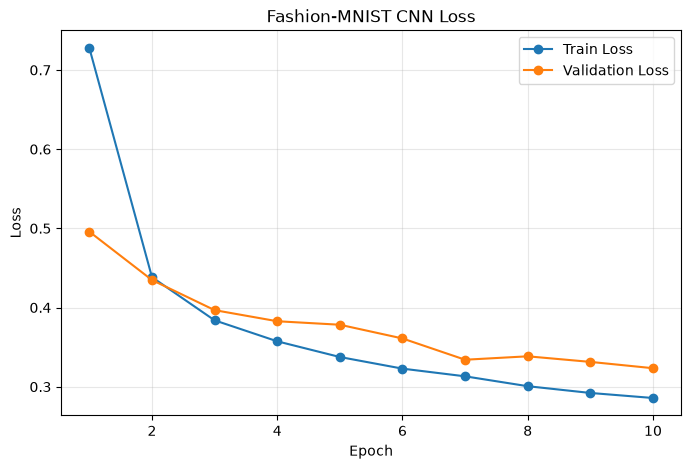

In [19]:
epoch_numbers = range(
    1,
    NUMBER_OF_EPOCHS + 1
)

plt.figure(figsize=(8, 5))

plt.plot(
    epoch_numbers,
    history["train_loss"],
    marker="o",
    label="Train Loss"
)

plt.plot(
    epoch_numbers,
    history["validation_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("Fashion-MNIST CNN Loss")

plt.grid(alpha=0.3)

plt.legend()

plt.show()

### 17) 학습 정확도 시각화

훈련 정확도와 검증 정확도의 차이가 지나치게 커지는지 확인합니다.

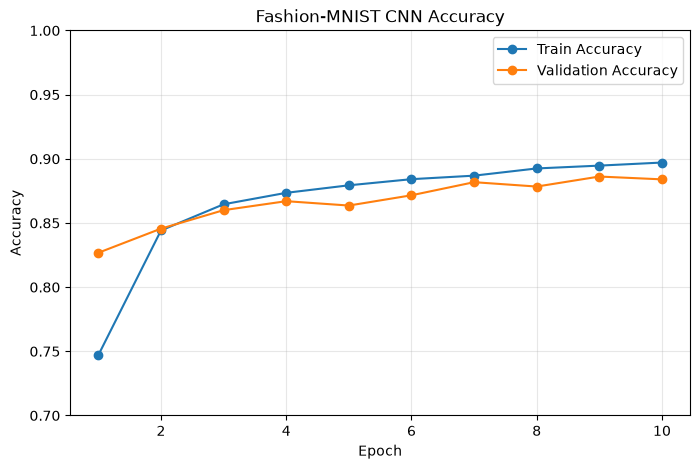

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(
    epoch_numbers,
    history["train_accuracy"],
    marker="o",
    label="Train Accuracy"
)

plt.plot(
    epoch_numbers,
    history["validation_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.title("Fashion-MNIST CNN Accuracy")

plt.ylim(0.7, 1.0)

plt.grid(alpha=0.3)

plt.legend()

plt.show()

### 18) 테스트 성능 확인

검증 데이터로 선택한 최고 가중치 하나만 테스트 데이터로 평가합니다.

In [21]:
test_loss, test_accuracy = evaluate_model(
    model,
    test_loader
)

print(f"테스트 손실: {test_loss:.4f}")

print(f"테스트 정확도: {test_accuracy:.4f}")

print(
    f"맞힌 이미지 수: "
    f"{int(test_accuracy * len(test_dataset)):,}"
    f" / {len(test_dataset):,}"
)

테스트 손실: 0.3301
테스트 정확도: 0.8838
맞힌 이미지 수: 8,838 / 10,000


### 19) 데이터 구조 확인

혼동행렬과 오답 분석에서 모델을 반복 실행하지 않도록 테스트 결과를 한 번에 모읍니다.

In [22]:
image_batches = []

label_batches = []

logit_batches = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        logits = model(
            images.to(device)
        ).cpu()

        image_batches.append(images)
        label_batches.append(labels)
        logit_batches.append(logits)

all_images = torch.cat(
    image_batches
)

all_labels = torch.cat(
    label_batches
)

all_logits = torch.cat(
    logit_batches
)

all_probabilities = torch.softmax(
    all_logits,
    dim=1
)

all_confidences, all_predictions = (
    all_probabilities.max(dim=1)
)

print("전체 이미지 Shape:", all_images.shape)

print("전체 예측 Shape:", all_predictions.shape)

전체 이미지 Shape: torch.Size([10000, 1, 28, 28])
전체 예측 Shape: torch.Size([10000])


### 20) Confusion Matrix 준비

```text
행: 실제 의류
열: 예측 의류
대각선: 올바른 예측
대각선 밖: 잘못된 예측
```

대각선 밖의 큰 값은 자주 혼동하는 의류 관계입니다.

In [23]:
confusion_matrix = torch.zeros(
    10,
    10,
    dtype=torch.int64
)

### 21) Confusion Matrix 계산

In [24]:
for actual, predicted in zip(
    all_labels,
    all_predictions
):
    confusion_matrix[
        actual,
        predicted
    ] += 1

### 22) Confusion Matrix 시각화

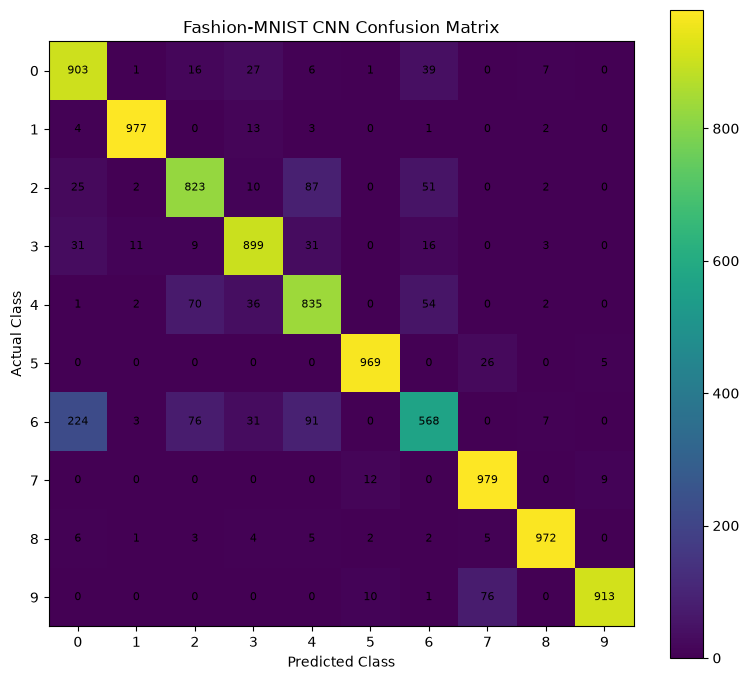

In [25]:
plt.figure(figsize=(8, 7))

plt.imshow(
    confusion_matrix.numpy()
)

plt.xticks(range(10))

plt.yticks(range(10))

plt.xlabel("Predicted Class")

plt.ylabel("Actual Class")

plt.title("Fashion-MNIST CNN Confusion Matrix")

for row in range(10):
    for column in range(10):
        plt.text(
            column,
            row,
            int(confusion_matrix[row, column]),
            ha="center",
            va="center",
            fontsize=8
        )

plt.colorbar()

plt.tight_layout()

plt.show()

### 23) 모델 구성

전체 정확도만 보면 어떤 의류에 약한지 알기 어렵습니다.

```text
클래스별 정확도
→ 해당 의류를 맞힌 개수
÷ 해당 의류의 전체 개수
```

In [26]:
class_correct = confusion_matrix.diag()

class_total = confusion_matrix.sum(
    dim=1
)

class_accuracy = (
    class_correct.float()
    / class_total
)

for class_index in range(10):
    print(
        f"{class_index}: "
        f"{class_names_ko[class_index]:<6} | "
        f"{class_accuracy[class_index].item():.4f}"
    )

lowest_class = torch.argmin(
    class_accuracy
).item()

print()

print(
    "가장 낮은 정확도의 의류:",
    class_names_ko[lowest_class]
)

0: 티셔츠    | 0.9030
1: 바지     | 0.9770
2: 풀오버    | 0.8230
3: 원피스    | 0.8990
4: 코트     | 0.8350
5: 샌들     | 0.9690
6: 셔츠     | 0.5680
7: 운동화    | 0.9790
8: 가방     | 0.9720
9: 앵클부츠   | 0.9130

가장 낮은 정확도의 의류: 셔츠


### 24) 클래스별 정확도 확인

/tmp/ipykernel_377765/405031376.py:27: UserWarning: Glyph 54000 (\N{HANGUL SYLLABLE TI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_377765/405031376.py:27: UserWarning: Glyph 49492 (\N{HANGUL SYLLABLE SYEO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_377765/405031376.py:27: UserWarning: Glyph 52768 (\N{HANGUL SYLLABLE CEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_377765/405031376.py:27: UserWarning: Glyph 48148 (\N{HANGUL SYLLABLE BA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_377765/405031376.py:27: UserWarning: Glyph 51648 (\N{HANGUL SYLLABLE JI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_377765/405031376.py:27: UserWarning: Glyph 54400 (\N{HANGUL SYLLABLE PUL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_377765/405031376.py:27: UserWarning: Glyph 50724 (\N{HANGUL SYLLABLE O}) missing from font(s) DejaVu Sans.
  plt.tigh

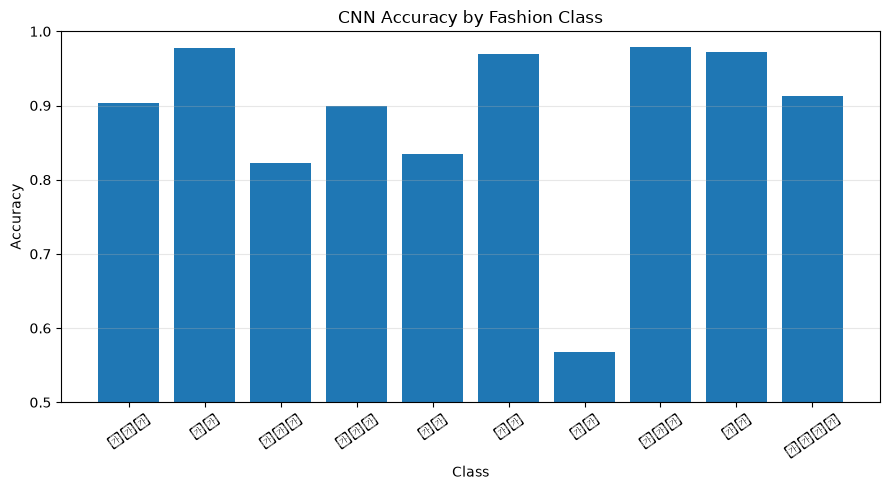

In [27]:
plt.figure(figsize=(9, 5))

plt.bar(
    range(10),
    class_accuracy.numpy()
)

plt.xticks(
    range(10),
    class_names_ko,
    rotation=35
)

plt.ylim(0.5, 1.0)

plt.xlabel("Class")

plt.ylabel("Accuracy")

plt.title("CNN Accuracy by Fashion Class")

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()

### 25) 주요 오분류 확인

혼동행렬의 대각선을 제외한 뒤 가장 큰 값을 찾습니다.

방향을 구분합니다.

```text
실제 셔츠 → 예측 티셔츠
```

위 관계와 `실제 티셔츠 → 예측 셔츠`는 서로 다른 오류입니다.

In [28]:
wrong_confusion = confusion_matrix.clone()

wrong_confusion.fill_diagonal_(0)

flat_index = wrong_confusion.argmax().item()

confused_actual = flat_index // 10

confused_predicted = flat_index % 10

confused_count = wrong_confusion[
    confused_actual,
    confused_predicted
].item()

print(
    f"실제 {class_names_ko[confused_actual]} "
    f"→ 예측 {class_names_ko[confused_predicted]}: "
    f"{confused_count}개"
)

실제 셔츠 → 예측 티셔츠: 224개


### 26) 오분류 데이터 확인

대표 오답 12개를 하나의 이미지 모음으로 확인합니다.

- `A`: 실제 클래스
- `P`: 예측 클래스
- `C`: 예측 확률

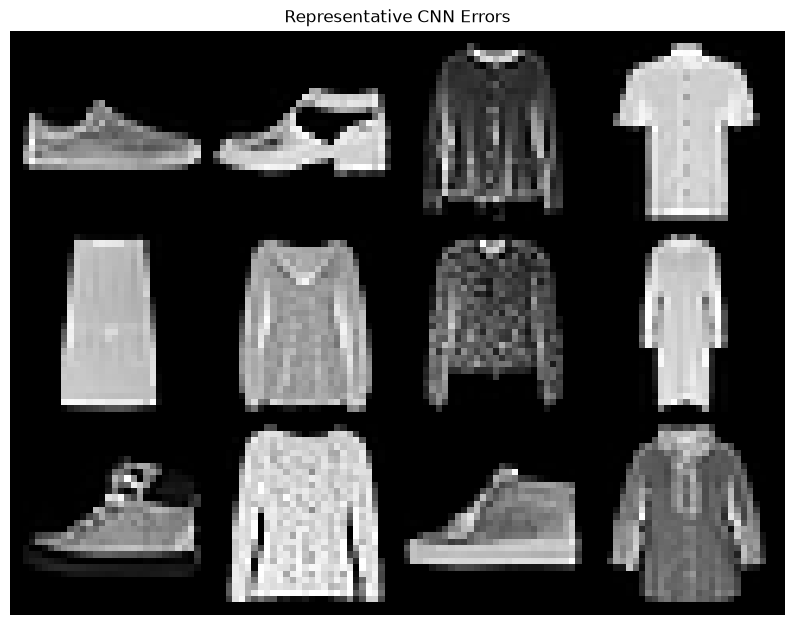

대표 오답


In [29]:
wrong_mask = (
    all_predictions != all_labels
)

wrong_images = all_images[
    wrong_mask
]

wrong_labels = all_labels[
    wrong_mask
]

wrong_predictions = all_predictions[
    wrong_mask
]

wrong_confidences = all_confidences[
    wrong_mask
]

number_of_examples = min(
    12,
    len(wrong_images)
)

wrong_grid = make_grid(
    wrong_images[:number_of_examples],
    nrow=4,
    padding=2
)

plt.figure(figsize=(10, 8))

plt.imshow(
    wrong_grid.permute(1, 2, 0)
)

plt.title("Representative CNN Errors")

plt.axis("off")

plt.show()

print("대표 오답")

### 27) 오분류 데이터 확인

In [30]:
for index in range(number_of_examples):
    actual_name = class_names_ko[
        wrong_labels[index].item()
    ]

    predicted_name = class_names_ko[
        wrong_predictions[index].item()
    ]

    print(
        f"{index:>2d} | "
        f"A:{actual_name:<6} | "
        f"P:{predicted_name:<6} | "
        f"C:{wrong_confidences[index].item():.3f}"
    )

 0 | A:운동화    | P:샌들     | C:0.832
 1 | A:앵클부츠   | P:샌들     | C:0.999
 2 | A:코트     | P:풀오버    | C:0.653
 3 | A:셔츠     | P:티셔츠    | C:0.910
 4 | A:원피스    | P:티셔츠    | C:0.462
 5 | A:풀오버    | P:셔츠     | C:0.765
 6 | A:코트     | P:풀오버    | C:0.386
 7 | A:원피스    | P:코트     | C:0.635
 8 | A:앵클부츠   | P:운동화    | C:0.967
 9 | A:셔츠     | P:풀오버    | C:0.472
10 | A:앵클부츠   | P:운동화    | C:0.930
11 | A:셔츠     | P:코트     | C:0.581


### 28) 2픽셀 이동 민감도

MLP에도 같은 실험을 적용합니다.

```text
원본 이미지
→ 오른쪽으로 2픽셀 이동
→ 새로 생긴 왼쪽 영역은 0으로 채움
```

사람에게는 같은 의류이지만 모델의 예측이 얼마나 바뀌는지 확인합니다.

In [31]:
def shift_right(
    images,
    pixels=2
):
    shifted = torch.zeros_like(
        images
    )

    shifted[
        :,
        :,
        :,
        pixels:
    ] = images[
        :,
        :,
        :,
        :-pixels
    ]

    return shifted

### 29) 테스트 성능 확인

In [32]:
shifted_correct = 0

prediction_changed = 0

total = 0

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        shifted_images = shift_right(
            images,
            pixels=2
        )

        original_predictions = model(
            images
        ).argmax(dim=1)

        shifted_predictions = model(
            shifted_images
        ).argmax(dim=1)

        shifted_correct += (
            shifted_predictions == labels
        ).sum().item()

        prediction_changed += (
            shifted_predictions
            != original_predictions
        ).sum().item()

        total += labels.size(0)

shifted_accuracy = (
    shifted_correct / total
)

prediction_change_rate = (
    prediction_changed / total
)

accuracy_drop = (
    test_accuracy - shifted_accuracy
)

print(f"원본 정확도: {test_accuracy:.4f}")

원본 정확도: 0.8838


### 30) 이동 이미지 성능 확인

In [33]:
print(
    f"2픽셀 이동 정확도: "
    f"{shifted_accuracy:.4f}"
)

print(
    f"정확도 감소: "
    f"{accuracy_drop:.4f}"
)

print(
    f"예측 클래스 변경 비율: "
    f"{prediction_change_rate:.4f}"
)

2픽셀 이동 정확도: 0.7469
정확도 감소: 0.1369
예측 클래스 변경 비율: 0.2169


### 31) 모델 저장

Checkpoint에는 다음 정보를 함께 저장합니다.

- CNN 가중치
- 합성곱 채널 수
- 이미지 크기
- 클래스 이름
- 최고 검증 Epoch와 성능
- 테스트 성능

저장한 Checkpoint는 필터와 특징맵 시각화에 사용합니다.

In [34]:
checkpoint_path = MODEL_DIR / "ch04_1_best_fashion_mnist_cnn.pt"

checkpoint = {
    "model_state_dict": model.state_dict(),
    "input_channels": 1,
    "feature_channels": [8, 16],
    "image_size": [1, 28, 28],
    "number_of_classes": 10,
    "class_names": class_names,
    "class_names_ko": class_names_ko,
    "best_epoch": best_epoch,
    "validation_loss": best_validation_loss,
    "validation_accuracy": best_validation_accuracy,
    "test_loss": test_loss,
    "test_accuracy": test_accuracy,
    "shifted_accuracy": shifted_accuracy
}

torch.save(
    checkpoint,
    checkpoint_path
)

loaded_checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

restored_model = make_cnn()

restored_model.load_state_dict(
    loaded_checkpoint[
        "model_state_dict"
    ]
)

restored_model.eval()

print("저장 파일:", checkpoint_path)

print(
    "저장된 검증 정확도:",
    f"{loaded_checkpoint['validation_accuracy']:.4f}"
)

print(
    "저장된 테스트 정확도:",
    f"{loaded_checkpoint['test_accuracy']:.4f}"
)

저장 파일: models/ch05_1_best_fashion_mnist_cnn.pt
저장된 검증 정확도: 0.8862
저장된 테스트 정확도: 0.8838
